In [12]:
from google.colab import drive
drive.mount('/content/drive/')


Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [14]:
import os
os.chdir("/content/drive/MyDrive/VTC_AI/comments_analysis/")


In [15]:
!ls

 bert
 bert_rep.npz
'Bert Text Representation Generation.ipynb'
 comments_analysis.ipynb
 imdb_sup.csv
 LSTM.IPYNB
 __pycache__
 SVM.IPYNB
'SVM Text Representation Generation.ipynb'
 tfidf_data.npz
 utils.py


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import re
from tqdm import tqdm
from transformers import BertTokenizer, BertModel
import torch
import numpy as np

In [ ]:
model_name = 'bert'
device = 'cuda'

In [ ]:

# load pre-trained BERT model and tokenizer
tokenizer = BertTokenizer.from_pretrained(model_name)
model = BertModel.from_pretrained(model_name)
model.to(device)  # move model to specified device

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(21128, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

In [ ]:
comments = pd.read_csv('./imdb_sup.csv')
def rate2label(rate):
    """
    1-10,Three classes
    :param rate:
    :return:
    """
    if rate <= 3:
        return 0
    elif rate <= 6:
        return 1
    else:
        return 2
comments['Rating'] = comments['Rating'].apply(lambda x: rate2label(x))

In [ ]:
all_comments = comments['Review'].values.tolist()
all_labels = comments['Rating'].values.tolist()
str_comments = [str(c) for c in all_comments]
select_idx = np.random.choice(len(str_comments), 10000, replace=False)
str_comments = [str_comments[i] for i in select_idx]
all_labels = [all_labels[i] for i in select_idx]

In [ ]:
# create linear layer, to reduce dimension
import torch.nn as nn
linear_layer = nn.Linear(768, 128).to(device)
def get_bert_embeddings(text):
    # ncode the input text
    encoded_input = tokenizer(text, return_tensors='pt', truncation=True,max_length=512)
    #  move encoded input to specified device
    encoded_input = {key: val.to(device) for key, val in encoded_input.items()}
    # obtain  BERT model output
    with torch.no_grad():
        output = model(**encoded_input)
        #  extract the hidden state of the last layer
        last_hidden_states = linear_layer(output.last_hidden_state)
    return last_hidden_states.squeeze(0)

In [ ]:
def pad_and_truncate(rep:torch.Tensor, max_len=128):
    length,dim = rep.shape
    if length > max_len:
        return rep[:max_len,:]
    else:
        return torch.cat((rep,torch.zeros(max_len-length,dim)),dim=0)

In [ ]:
bert_rep = []
for s in tqdm(str_comments):
    rep =get_bert_embeddings(s).cpu()
    rep = pad_and_truncate(rep)
    bert_rep.append(rep)


100%|██████████| 10000/10000 [04:30<00:00, 37.02it/s]


In [ ]:
bert_rep = np.array([i.numpy() for i in tqdm(bert_rep)])
np.savez('./bert_rep.npz',bert_rep=bert_rep,all_labels=all_labels)

100%|██████████| 10000/10000 [00:00<00:00, 334103.66it/s]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import re
from tqdm import tqdm
import numpy as np


In [ ]:
comments = pd.read_csv('./imdb_sup.csv')
def rate2label(rate):
    """
    1-10,Three classes
    :param rate:
    :return:
    """
    if rate <= 3:
        return 0
    elif rate <= 6:
        return 1
    else:
        return 2
comments['Rating'] = comments['Rating'].apply(lambda x: rate2label(x))

In [ ]:
all_comments = comments['Review'].values.tolist()
all_labels = comments['Rating'].values.tolist()
str_comments = [str(c) for c in all_comments]
select_idx = np.random.choice(len(str_comments), 10000, replace=False)
str_comments = [str_comments[i] for i in select_idx]
all_labels = [all_labels[i] for i in select_idx]

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
tfidf_vectorizer = TfidfVectorizer(max_features=128)
X = tfidf_vectorizer.fit_transform(str_comments)
X_train, X_test, y_train, y_test = train_test_split(X, all_labels, test_size=0.2, random_state=42)
np.savez('./tfidf_data.npz', X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,X=X.toarray(),y=all_labels)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import numpy as np
from utils import  plot_confusion_matrix

In [ ]:
main_data = np.load('./tfidf_data.npz',allow_pickle=True)

In [ ]:
X = main_data['X']
Y = main_data['y']
Y = np.array(Y)

In [ ]:
num_cls = len(set(Y))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, metrics
from sklearn.model_selection import StratifiedKFold
from matplotlib.font_manager import FontProperties
plt.rcParams['axes.unicode_minus']=False       #显示负号
plt.rcParams['font.size'] = 12

In [ ]:

# set new_roman font
font = FontProperties(family='Times New Roman', size=12)


# define 5-fold cross validation
cv = StratifiedKFold(n_splits=2)


# initialize lists to store results
all_y_true = []
all_y_pred = []
all_y_prob = []

# start 5 cross validation
for train_index, test_index in cv.split(X, Y):
    # split data
    X_train, X_test = X[train_index], X[test_index]
    Y_train, Y_test = Y[train_index], Y[test_index]

    # create and train SVM model
    clf = svm.SVC(kernel='rbf', probability=True)
    clf.fit(X_train, Y_train)

    # predict and get probability
    Y_pred = clf.predict(X_test)
    Y_prob = clf.predict_proba(X_test)

    # collect all results
    all_y_true.extend(Y_test)
    all_y_pred.extend(Y_pred)
    all_y_prob.extend(Y_prob)

# list2numpy
all_y_true = np.array(all_y_true)
all_y_pred = np.array(all_y_pred)
all_y_prob = np.array(all_y_prob)
y_test = all_y_true
y_pred = all_y_pred

In [ ]:
mm = 'SVM'

Normalized confusion matrix


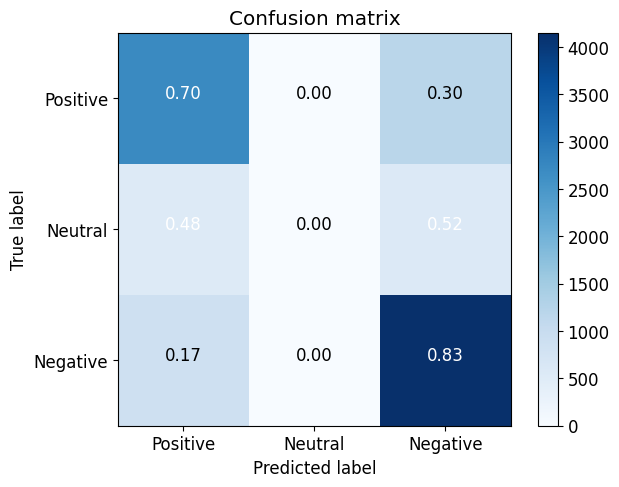

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(cm,classes=['Positive', 'Neutral', 'Negative'],normalize=True,title='Confusion matrix')

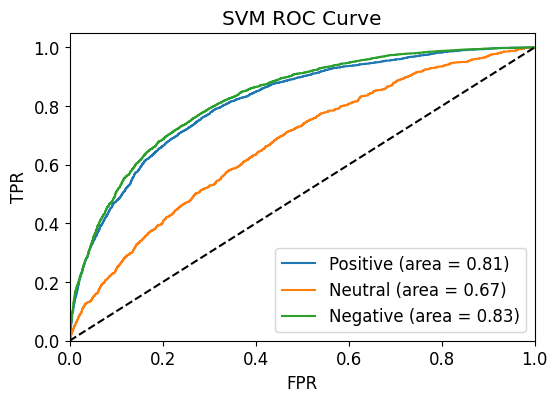

              precision    recall  f1-score   support

           0       0.66      0.70      0.68      3896
           1       0.00      0.00      0.00      1085
           2       0.70      0.83      0.76      5019

    accuracy                           0.69     10000
   macro avg       0.45      0.51      0.48     10000
weighted avg       0.61      0.69      0.65     10000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
CCC = ['Positive', 'Neutral', 'Negative']
fpr = dict()
tpr = dict()
roc_auc = dict()
plt.figure(figsize=(6, 4),dpi=100)
for i in range(num_cls):
    fpr[i], tpr[i], _ = metrics.roc_curve((all_y_true == i).astype(int), all_y_prob[:, i])
    roc_auc[i] = metrics.auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'{CCC[i]} (area = {roc_auc[i]:0.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title(f'{mm} ROC Curve')
plt.legend(loc="lower right")
plt.show()


print(metrics.classification_report(all_y_true, all_y_pred))

# LSTM

In [ ]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import tensorflow as tf
import matplotlib.pyplot as plt
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['font.size'] = 12

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,923 (226.26 KB)

 Trainable params: 57,923 (226.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.4684 - loss: 0.9747 - val_accuracy: 0.4960 - val_loss: 0.9597
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.5123 - loss: 0.9311 - val_accuracy: 0.5530 - val_loss: 0.9221
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5442 - loss: 0.9217 - val_accuracy: 0.5370 - val_loss: 0.9323
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.5604 - loss: 0.9114 - val_accuracy: 0.5590 - val_loss: 0.9164
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5985 - loss: 0.8828 - val_accuracy: 0.5590 - val_loss: 0.9107
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5766 - loss: 0.9041 - val_accuracy: 0.5700 - val_loss: 0.8972
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6050 - loss: 0.8598 - val_accuracy: 0.5835 - val_loss: 0.8892
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6281 - loss: 0.8428 - 

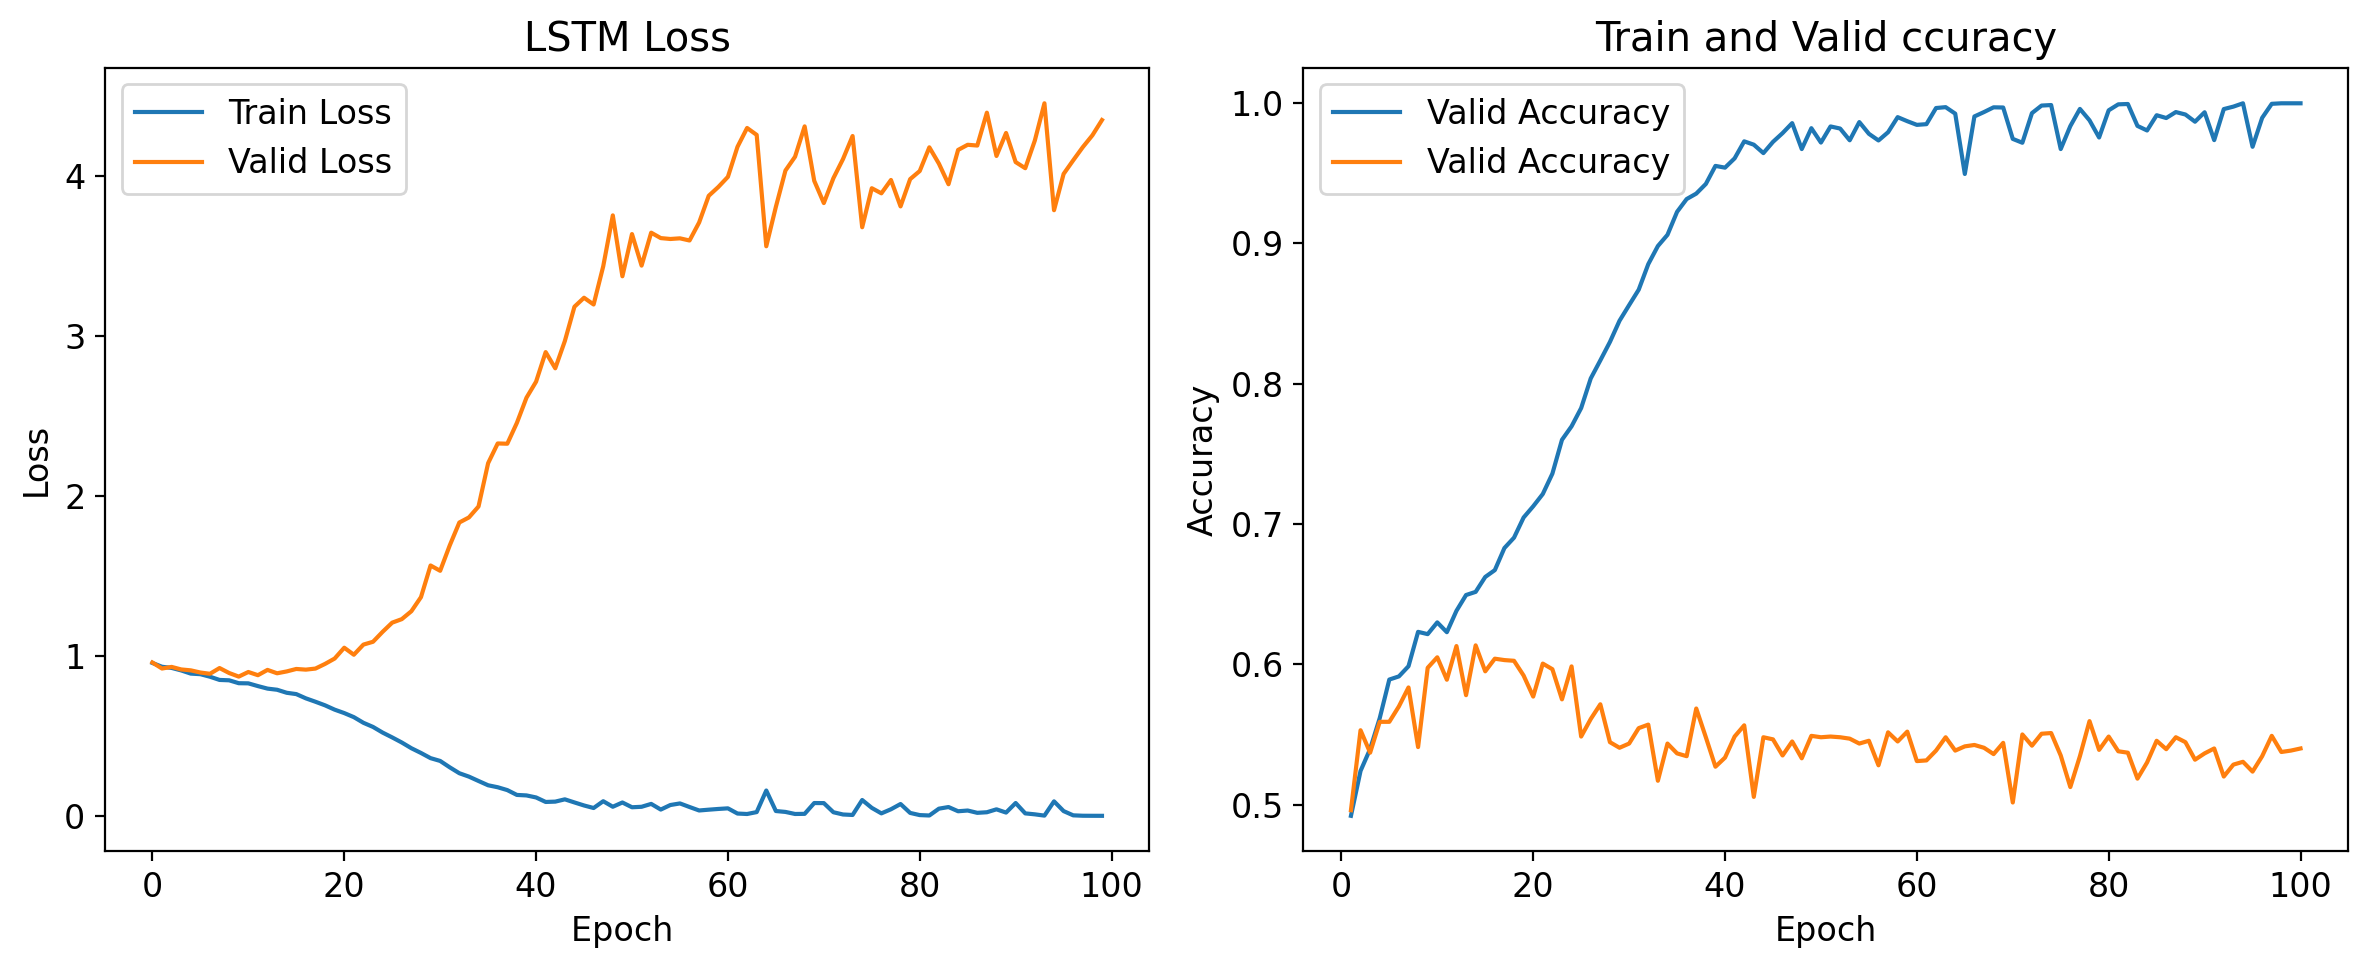

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5303 - loss: 4.4894
Test accuracy: 0.5400
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
F1 Score: 0.5385
Precision: 0.5377
Recall: 0.5400
Classification Report:
              precision    recall  f1-score   support

    Positive       0.55      0.52      0.53       800
     Neutral       0.13      0.12      0.13       208
    Negative       0.62      0.65      0.63       992

    accuracy                           0.54      2000
   macro avg       0.43      0.43      0.43      2000
weighted avg       0.54      0.54      0.54      2000

Normalized confusion matrix


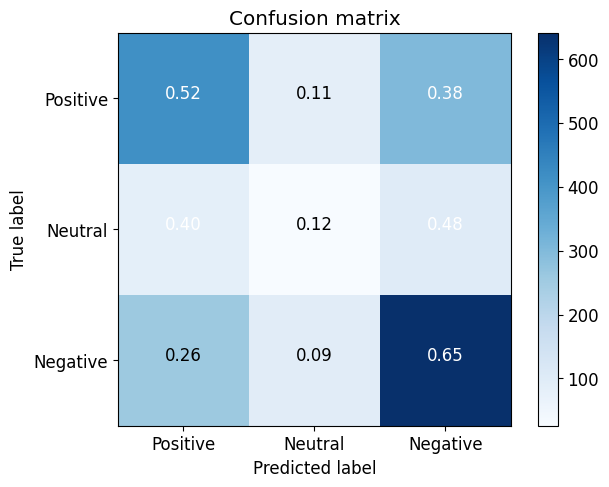

In [ ]:




data = np.load('./bert_rep.npz')
y = data['all_labels']
data = data['bert_rep']



from keras.utils import to_categorical
y = to_categorical(y)
X_train, X_test, y_train, y_test  = train_test_split(data, y, test_size=0.2, random_state=42, stratify=y)


from keras.models import Model
from keras.layers import Dense,Input,LSTM,Reshape,Flatten,Conv1D
from keras.optimizers import  Adam
inp = Input((128,128))
temp = LSTM(64)(inp)
temp = Flatten()(temp)
temp = Dense(64,activation='relu')(temp)
temp = Dense(64,activation='relu')(temp)
out = Dense(3,activation='softmax')(temp)
model=Model(inputs=[inp],outputs=[out])
model.summary()



model.compile(optimizer=Adam(0.0005), loss='categorical_crossentropy', metrics=['accuracy'])


X_train.shape


history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test))


# model.save_weights('./CNN_model_weights.weights.h5')


mm = 'LSTM'


plt.figure(figsize=(12, 5),dpi=200)

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Valid Loss')
plt.xlabel('Epoch ')
plt.ylabel('Loss')
plt.title(f'{mm} Loss')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(range(1, len(history.history['accuracy']) + 1), history.history['accuracy'], label='Valid Accuracy')
plt.plot(range(1, len(history.history['val_accuracy']) + 1), history.history['val_accuracy'], label='Valid Accuracy')
plt.xlabel('Epoch')  #
plt.ylabel('Accuracy')
plt.title('Train and Valid ccuracy')
plt.legend()

plt.tight_layout()
plt.show()


from sklearn.metrics import classification_report, f1_score, precision_score, recall_score



test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_accuracy:.4f}")


predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)


f1 = f1_score(np.argmax(y_test,axis=1), predicted_classes,average='weighted')
precision = precision_score(np.argmax(y_test,axis=1), predicted_classes,average='weighted')
recall = recall_score(np.argmax(y_test,axis=1), predicted_classes,average='weighted')


print(f"F1 Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")


report = classification_report(np.argmax(y_test,axis=1), predicted_classes, target_names=['Positive', 'Neutral', 'Negative'])
print("Classification Report:")
print(report)


cm = confusion_matrix(np.argmax(y_test,axis=1), predicted_classes,)
from utils import plot_confusion_matrix
plot_confusion_matrix(cm,classes=['Positive', 'Neutral', 'Negative'],normalize=True,title='Confusion matrix')


